Experiments on simulated data to check whether changes really work: A/B tests, corrections, power, peeking, Bayesian, matching, DiD, and DoWhy/EconML.


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(42)
n = 5000

control = rng.binomial(1, 0.10, n)    # 10% convert without the change
treatment = rng.binomial(1, 0.12, n)  # 12% convert with the change

print("Control rate:", control.mean().round(4))
print("Treatment rate:", treatment.mean().round(4))

Control rate: 0.0986
Treatment rate: 0.118


In [ ]:
p_pool = (control.sum() + treatment.sum()) / (2 * n)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n + 1/n))
z = (treatment.mean() - control.mean()) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

print("z-score:", round(z, 3))
print("p-value:", round(p_value, 4))

z-score: 3.121
p-value: 0.0018


In [ ]:
diff = treatment.mean() - control.mean()
se_diff = np.sqrt(treatment.mean()*(1-treatment.mean())/n + control.mean()*(1-control.mean())/n)
ci_low = diff - 1.96 * se_diff
ci_high = diff + 1.96 * se_diff

print("Difference:", round(diff, 4))
print("95% CI:", round(ci_low, 4), "to", round(ci_high, 4))

Difference: 0.0194
95% CI: 0.0072 to 0.0316


In [ ]:
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(7)
p_values = []
for i in range(20):
    a = rng.binomial(1, 0.10, 5000)  # control
    b = rng.binomial(1, 0.10, 5000)  # variant with the same true rate
    pooled = (a.sum() + b.sum()) / 10000
    se = np.sqrt(pooled * (1 - pooled) * (2 / 5000))
    z = (b.mean() - a.mean()) / se
    p_values.append(2 * (1 - stats.norm.cdf(abs(z))))
p_values = np.array(p_values)

print("Raw wins (p < 0.05):", (p_values < 0.05).sum())

Raw wins (p < 0.05): 2


In [ ]:
bonf = multipletests(p_values, method='bonferroni')[1]
bh = multipletests(p_values, method='fdr_bh')[1]

print("Bonferroni wins:", (bonf < 0.05).sum())
print("Benjamini-Hochberg wins:", (bh < 0.05).sum())

Bonferroni wins: 0
Benjamini-Hochberg wins: 0


In [ ]:
rng = np.random.default_rng(7)
p_real = []
for i in range(20):
    a = rng.binomial(1, 0.10, 5000)
    true_b = 0.13 if i == 0 else 0.10  # only test 0 has a real 3-point gain
    b = rng.binomial(1, true_b, 5000)
    pooled = (a.sum() + b.sum()) / 10000
    se = np.sqrt(pooled * (1 - pooled) * (2 / 5000))
    z = (b.mean() - a.mean()) / se
    p_real.append(2 * (1 - stats.norm.cdf(abs(z))))
p_real = np.array(p_real)

print("Raw wins:", (p_real < 0.05).sum())
print("Bonferroni wins:", (multipletests(p_real, method='bonferroni')[1] < 0.05).sum())
print("Benjamini-Hochberg wins:", (multipletests(p_real, method='fdr_bh')[1] < 0.05).sum())
print("Test 0 p-value after BH:", round(multipletests(p_real, method='fdr_bh')[1][0], 4))

Raw wins: 2
Bonferroni wins: 1
Benjamini-Hochberg wins: 1
Test 0 p-value after BH: 0.0


In [ ]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

effect = proportion_effectsize(0.12, 0.10)   # size of the change, on a standard scale
n_per_group = NormalIndPower().solve_power(effect_size=effect, alpha=0.05,
                                           power=0.8, ratio=1,
                                           alternative='two-sided')
print("Effect size:", round(effect, 4))
print("Visitors needed per group:", round(n_per_group))

Effect size: 0.064
Visitors needed per group: 3835


In [ ]:
effect_small = proportion_effectsize(0.11, 0.10)
n_small = NormalIndPower().solve_power(effect_size=effect_small, alpha=0.05,
                                       power=0.8, ratio=1, alternative='two-sided')
print("Visitors needed per group for a 1-point change:", round(n_small))

Visitors needed per group for a 1-point change: 14744


In [ ]:
!pip install fastapi httpx -q

In [ ]:
%%writefile power_api.py
from fastapi import FastAPI
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

app = FastAPI()

@app.get("/sample-size")
def sample_size(baseline: float, expected: float, alpha: float = 0.05, power: float = 0.8):
    effect = proportion_effectsize(expected, baseline)
    n = NormalIndPower().solve_power(effect_size=effect, alpha=alpha,
                                     power=power, ratio=1, alternative='two-sided')
    return {"visitors_per_group": int(round(n))}

Writing power_api.py


In [ ]:
from fastapi.testclient import TestClient
from power_api import app

client = TestClient(app)
print(client.get("/sample-size", params={"baseline": 0.10, "expected": 0.12}).json())

{'visitors_per_group': 3835}


In [ ]:
print(client.get("/sample-size", params={"baseline": 0.10, "expected": 0.11}).json())

{'visitors_per_group': 14744}


In [ ]:
rng = np.random.default_rng(11)
peek_wins = 0
fixed_wins = 0

for _ in range(1000):
    a = rng.binomial(1, 0.10, 5000)
    b = rng.binomial(1, 0.10, 5000)  # same true rate, so no real effect
    stopped_early = False
    for n in range(500, 5001, 500):
        pooled = (a[:n].sum() + b[:n].sum()) / (2 * n)
        se = np.sqrt(pooled * (1 - pooled) * (2 / n))
        if se == 0:
            continue
        z = (b[:n].mean() - a[:n].mean()) / se
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        if p < 0.05:
            stopped_early = True
            break
    if stopped_early:
        peek_wins += 1
    # the fixed rule: look only once, at the end
    pooled = (a.sum() + b.sum()) / 10000
    se = np.sqrt(pooled * (1 - pooled) * (2 / 5000))
    z = (b.mean() - a.mean()) / se
    if 2 * (1 - stats.norm.cdf(abs(z))) < 0.05:
        fixed_wins += 1

print("False wins when peeking:", peek_wins, "out of 1000")
print("False wins with one look:", fixed_wins, "out of 1000")

False wins when peeking: 188 out of 1000
False wins with one look: 49 out of 1000


In [ ]:
rng = np.random.default_rng(11)
fixed_peek_wins = 0

for _ in range(1000):
    a = rng.binomial(1, 0.10, 5000)
    b = rng.binomial(1, 0.10, 5000)
    stopped_early = False
    for n in range(500, 5001, 500):
        pooled = (a[:n].sum() + b[:n].sum()) / (2 * n)
        se = np.sqrt(pooled * (1 - pooled) * (2 / n))
        if se == 0:
            continue
        z = (b[:n].mean() - a[:n].mean()) / se
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        if p < 0.005:
            stopped_early = True
            break
    if stopped_early:
        fixed_peek_wins += 1

print("False wins with strict peeking rule:", fixed_peek_wins, "out of 1000")

False wins with strict peeking rule: 19 out of 1000


In [ ]:
!pip install pymc -q
import pymc as pm

In [ ]:
with pm.Model():
    p_a = pm.Beta("p_a", alpha=1, beta=1)
    p_b = pm.Beta("p_b", alpha=1, beta=1)
    pm.Bernoulli("obs_a", p=p_a, observed=control)
    pm.Bernoulli("obs_b", p=p_b, observed=treatment)
    trace = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)

In [ ]:
p_a_samples = trace.posterior["p_a"].values.flatten()
p_b_samples = trace.posterior["p_b"].values.flatten()

prob_b_better = (p_b_samples > p_a_samples).mean()
print("Probability B beats A:", round(prob_b_better, 3))
print("Average lift:", round((p_b_samples - p_a_samples).mean(), 4))

Probability B beats A: 0.999
Average lift: 0.0195


In [ ]:
rng = np.random.default_rng(21)
n = 10000

engagement = rng.normal(0, 1, n)                       # how active the customer is
p_treat = 1 / (1 + np.exp(-0.8 * engagement))          # engaged customers get the offer more often
treated = rng.binomial(1, p_treat)

true_effect = 0.05                                      # the offer adds 5 points, by construction
p_outcome = np.clip(0.2 + 0.1 * engagement + true_effect * treated, 0, 1)
outcome = rng.binomial(1, p_outcome)

obs = pd.DataFrame({'engagement': engagement, 'treated': treated, 'outcome': outcome})
print(obs.groupby('treated')['outcome'].mean().round(3))
print("Naive gap:", round(obs.loc[obs.treated == 1, 'outcome'].mean() - obs.loc[obs.treated == 0, 'outcome'].mean(), 3))

treated
0    0.164
1    0.292
Name: outcome, dtype: float64
Naive gap: 0.128


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

ps_model = LogisticRegression().fit(obs[['engagement']], obs['treated'])
obs['propensity'] = ps_model.predict_proba(obs[['engagement']])[:, 1]

treated_df = obs[obs.treated == 1]
control_df = obs[obs.treated == 0]

nn = NearestNeighbors(n_neighbors=1).fit(control_df[['propensity']])
_, idx = nn.kneighbors(treated_df[['propensity']])
matched_controls = control_df.iloc[idx.ravel()]

matched_gap = treated_df['outcome'].mean() - matched_controls['outcome'].mean()
print("Matched gap:", round(matched_gap, 3))

Matched gap: 0.047


In [ ]:
rng = np.random.default_rng(5)
rows = []
for unit in range(200):
    treated_unit = unit < 100              # first 100 units get the change
    unit_effect = rng.normal(0, 2)         # each unit has its own baseline
    for period in [0, 1]:                  # 0 = before, 1 = after
        trend = 1.5 * period               # trend that hits everyone
        effect = 4.0 if (treated_unit and period == 1) else 0.0  # true effect = 4
        y = 20 + unit_effect + trend + effect + rng.normal(0, 1)
        rows.append({'unit': unit, 'treated': int(treated_unit),
                     'after': period, 'y': y})
did_df = pd.DataFrame(rows)

means = did_df.groupby(['treated', 'after'])['y'].mean().unstack()
print(means.round(2))

after        0      1
treated              
0        19.74  21.37
1        19.88  25.34


In [ ]:
change_treated = means.loc[1, 1] - means.loc[1, 0]
change_control = means.loc[0, 1] - means.loc[0, 0]
did_estimate = change_treated - change_control
print("DiD estimate:", round(did_estimate, 3))

DiD estimate: 3.844


In [ ]:
!pip install dowhy econml -q

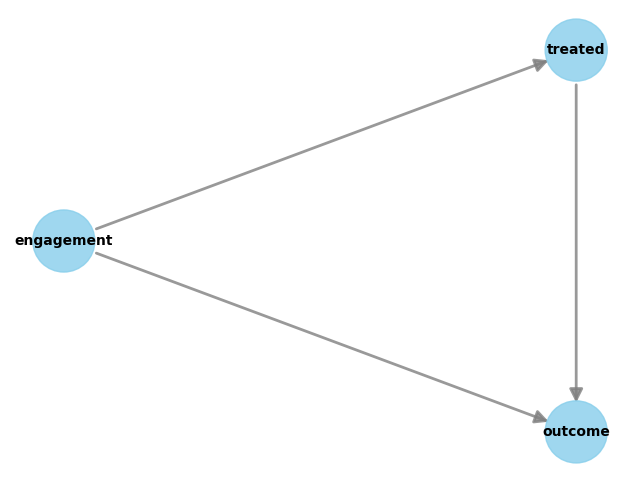

In [ ]:
from dowhy import CausalModel

model = CausalModel(
    data=obs,
    treatment='treated',
    outcome='outcome',
    common_causes=['engagement'],
)
model.view_model()

In [ ]:
model = CausalModel(
    data=obs[['engagement', 'treated', 'outcome']],
    treatment='treated',
    outcome='outcome',
    common_causes=['engagement'],
)

In [ ]:
identified = model.identify_effect(proceed_when_unidentifiable=True)
print(identified)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
    d                            
──────────(E[outcome|engagement])
d[treated]                       
Estimand assumption 1, Unconfoundedness: If U→{treated} and U→outcome then P(outcome|treated,engagement,U) = P(outcome|treated,engagement)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
    d                            
──────────(E[outcome|engagement])
d[treated]                       
Estimand assumption 1, Unconfoundedness: If U→{treated} and U→outcome then P(outcome|treated,engagement,U) = P(outcome|treated,engagement)



In [ ]:
estimate = model.estimate_effect(
    identified,
    method_name="backdoor.linear_regression",
)
print(estimate.value)

0.06080696823991946


In [ ]:
from econml.dml import LinearDML
from sklearn.linear_model import LassoCV

dml = LinearDML(model_y=LassoCV(), model_t=LassoCV(), random_state=42)
dml.fit(Y=obs['outcome'].values, T=obs['treated'].values,
        X=None, W=obs[['engagement']].values)
print("DML effect:", round(dml.ate(X=None), 3))

DML effect: 0.06
